# Ordering in Cu–Pt, from structures to phase diagram

A complete workflow in one notebook: build the structures with ASE, compute phonons with phonopy, and hand the results to landau. The disordered fcc alloy competes with three ordered compounds (Cu$_3$Pt, CuPt, CuPt$_3$).

We use the EMT potential because it is fast and comes with ASE. It is not fitted to Cu–Pt, so the diagram shows the workflow and not the real alloy.

Force constants are stored in `cache/`, so the notebook takes a few minutes. Without the cache it recomputes them, which takes about ten minutes more.

Saves all figures to `figures/`.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import phonopy
import structuretoolkit as stk
from ase import Atoms
from ase.build import bulk
from ase.calculators.emt import EMT
from ase.filters import FrechetCellFilter
from ase.optimize import BFGS
from phonopy import Phonopy
from phonopy.structure.atoms import PhonopyAtoms

from landau import PhonopyQuasiHarmonicPhase, Surface2DInterpolatingPhase
from landau.calculate import calc_phase_diagram
from landau.interpolate import CalphadSurface2DInterpolator, SplineFit
from landau.phases.quasiharmonic import EosExtrapolationWarning
from landau.plot import plot_mu_phase_diagram, plot_phase_diagram

warnings.filterwarnings("ignore", category=EosExtrapolationWarning)
warnings.filterwarnings("ignore", message=".*produced an invalid polygon")

/tmp/claude-1000/-home-pmrv-science-umich-projects-2026-11-MMM-LANDAU-POSTER-figures/5c1fa759-a059-4636-94b7-fd2951bd1356/scratchpad/fresh/.pixi/envs/default/lib/python3.12/site-packages/structuretoolkit/analyse/neighbors.py:667: SyntaxWarning: invalid escape sequence '\p'
  Y^m_l(\theta,\phi) = \sqrt{\frac{2l+1}{4\pi} \frac{(l-m)!}{(l+m)!}}


## Settings

In [2]:
A, B = "Cu", "Pt"
LATTICE_GUESS = {"Cu": 3.61, "Pt": 3.92}
T_MIN, T_MAX = 200, 700
MU_RANGE = (-0.7, 0.5)  # eV

STRAINS = np.linspace(-0.02, 0.03, 6)
SQS_REPEAT = 2  # SQS cells are 2x2x2 conventional fcc cells (32 atoms)
CACHE = Path("cache") / f"strain{STRAINS[0]:+.2f}{STRAINS[-1]:+.2f}x{len(STRAINS)}_sqs{SQS_REPEAT}"
CACHE.mkdir(parents=True, exist_ok=True)
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

FIGSIZE = (6.4, 4.8)
FONTSIZE = 13
DPI = 200

plt.style.use("default")
plt.rcParams.update({"font.size": FONTSIZE, "svg.fonttype": "none"})


def save(fig, name):
    for ax in fig.axes:  # keep the SVGs small: colour fields go in as images
        for artist in ax.collections:
            if type(artist).__name__ == "QuadMesh":
                artist.set_rasterized(True)
    fig.savefig(FIGURES / f"{name}.svg", dpi=DPI)
    fig.savefig(FIGURES / f"{name}.png", dpi=DPI, transparent=True)

## Structures

The ordered compounds use the 4-atom fcc cell. The disordered alloy uses 32-atom special quasirandom structures (SQS) from `structuretoolkit`.

In [3]:
def fcc(element, a=None):
    return bulk(element, "fcc", a=a or LATTICE_GUESS[element], cubic=True)


def lattice(x):
    return (1 - x) * LATTICE_GUESS[A] + x * LATTICE_GUESS[B]


def ordered(n_B):
    """L1_2 Cu3Pt (n_B = 1), L1_0 CuPt (2) or L1_2 CuPt3 (3)."""
    atoms = fcc(A, lattice(n_B / 4))
    symbols = atoms.get_chemical_symbols()
    for i in range(n_B):
        symbols[i] = B
    atoms.set_chemical_symbols(symbols)
    return atoms


def sqs(x, seed=42):
    n = 4 * SQS_REPEAT**3
    n_B = round(x * n)
    result = stk.build.sqs_structures(
        fcc(A, lattice(x)), {A: n - n_B, B: n_B},
        supercell=(SQS_REPEAT,) * 3,
        shell_weights={1: 1.0, 2: 0.5, 3: 0.25},
        iterations=500_000,
        max_results_per_objective=1,
        num_threads=1,
        seed=seed,
    )
    return result.best().atoms()

## Free energies from phonons

Each structure is relaxed and strained, and phonopy computes its phonons at every strain. landau takes these phonopy objects directly through `PhonopyQuasiHarmonicPhase`.

In [4]:
def relax(atoms, cell=True, fmax=1e-3):
    atoms = atoms.copy()
    atoms.calc = EMT()
    BFGS(FrechetCellFilter(atoms) if cell else atoms, logfile=None).run(fmax=fmax, steps=500)
    return atoms


def emt_forces(cell):
    atoms = Atoms(cell.symbols, cell=cell.cell, scaled_positions=cell.scaled_positions, pbc=True)
    atoms.calc = EMT()
    return atoms.get_forces()


def compute_phonons(atoms, path):
    repeat = max(1, round((4 * SQS_REPEAT**3 / len(atoms)) ** (1 / 3)))
    unitcell = PhonopyAtoms(
        symbols=atoms.get_chemical_symbols(), cell=atoms.cell[:], scaled_positions=atoms.get_scaled_positions()
    )
    ph = Phonopy(unitcell, supercell_matrix=np.eye(3) * repeat, primitive_matrix="auto")
    ph.generate_displacements(distance=0.01)
    ph.forces = [emt_forces(sc) for sc in ph.supercells_with_displacements]
    ph.produce_force_constants()
    ph.save(path, settings={"force_constants": True})


def load_phonons(path):
    ph = phonopy.load(path, log_level=0)
    ph.run_mesh(40.0)
    ph.run_thermal_properties(exclude_gamma_acoustic=True)
    return ph


def qha_phase(name, x, key, build):
    """Quasi-harmonic line phase for the structure from build(), cached under key."""
    energy_file = CACHE / f"{key}.json"
    if not energy_file.exists():
        relaxed = relax(build())
        energies = []
        for i, strain in enumerate(STRAINS):
            strained = relaxed.copy()
            strained.set_cell(relaxed.cell * (1 + strain), scale_atoms=True)
            strained = relax(strained, cell=False)
            energies.append(strained.get_potential_energy())
            compute_phonons(strained, CACHE / f"{key}_{i}.yaml")
        energy_file.write_text(json.dumps(energies))
    energies = json.loads(energy_file.read_text())
    phonopys = [load_phonons(CACHE / f"{key}_{i}.yaml") for i in range(len(STRAINS))]
    return PhonopyQuasiHarmonicPhase.from_phonopy(name, x, phonopys, energies)

## Phases

landau fits one CALPHAD-style free energy surface through the pure elements and the three SQS. The ordered compounds are line phases with a fixed composition.

In [5]:
pure = [qha_phase("fcc Cu", 0.0, A, lambda: fcc(A)), qha_phase("fcc Pt", 1.0, B, lambda: fcc(B))]
sqs_phases = [qha_phase(f"SQS x={x}", x, f"{A}{B}_sqs{int(x * 100)}", lambda: sqs(x)) for x in (0.25, 0.5, 0.75)]

solid = Surface2DInterpolatingPhase(
    "fcc",
    phases=[pure[0], *sqs_phases, pure[1]],
    add_entropy=True,
    surface_interpolator=CalphadSurface2DInterpolator(num_coeffs=3, coeff_poly_order=2, terminal_interpolator=SplineFit()),
    temperature_range=(0, T_MAX),
    num_temperature_samples=60,
)
compounds = [
    qha_phase(r"Cu$_3$Pt", 0.25, f"{A}{B}_L12_A3B", lambda: ordered(1)),
    qha_phase("CuPt", 0.50, f"{A}{B}_L10", lambda: ordered(2)),
    qha_phase(r"CuPt$_3$", 0.75, f"{A}{B}_L12_AB3", lambda: ordered(3)),
]
phases = [solid, *compounds]

## Phase diagram

One calculation gives one table, and landau draws two diagrams from it: temperature against concentration and temperature against chemical potential.

In [6]:
diagram = calc_phase_diagram(phases, Ts=np.linspace(T_MIN, T_MAX, 100), mu=200)

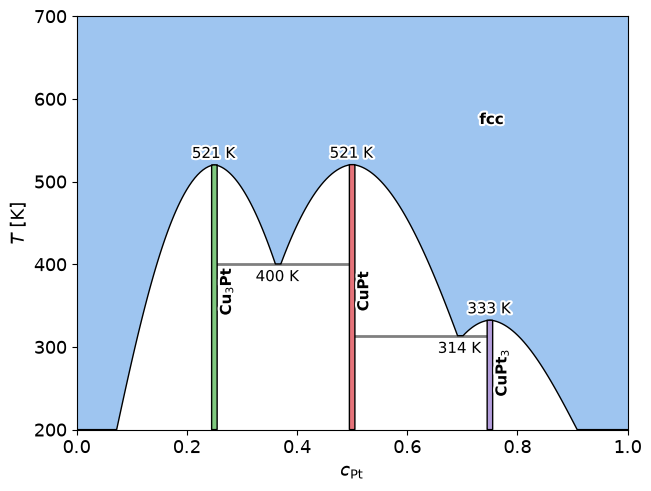

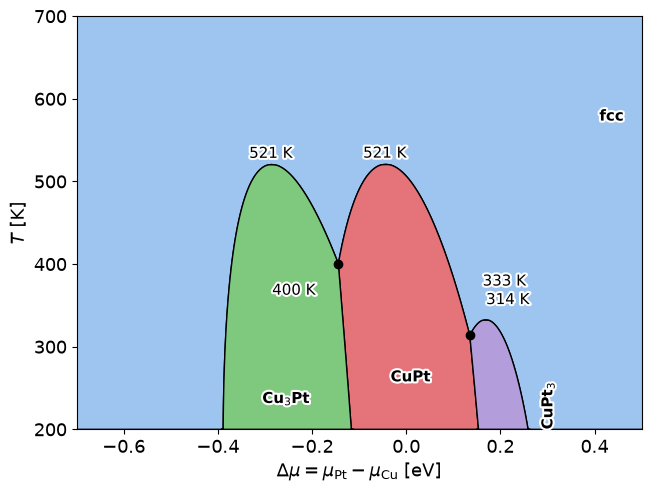

In [7]:
PASTEL = {"fcc": "#9ec5f0", r"Cu$_3$Pt": "#7fc97f", "CuPt": "#e5737a", r"CuPt$_3$": "#b39ddb"}
PLOTS = {"cT": plot_phase_diagram, "muT": plot_mu_phase_diagram}


def finish(ax, kind):
    if kind == "muT":
        ax.set_xlim(*MU_RANGE)
        ax.set_xlabel(r"$\Delta\mu = \mu_\mathrm{Pt} - \mu_\mathrm{Cu}$ [eV]")
    else:
        ax.set_xlabel(r"$c_\mathrm{Pt}$")


for kind, plot in PLOTS.items():
    fig, ax = plt.subplots(figsize=FIGSIZE, layout="constrained")
    plot(diagram, ax=ax, element=B, color_override=PASTEL, transition_temperatures=True, triplepoints=True)
    finish(ax, kind)
    save(fig, f"CuPt_{kind}_T_lines")

## Colouring by other quantities

Phase fields can be filled with any numeric column of the table through `color_by`. Here the concentration diagram shows the chemical potential and the other way around. The formation free energy `f_excess` did not fit on the poster, so it appears only here.

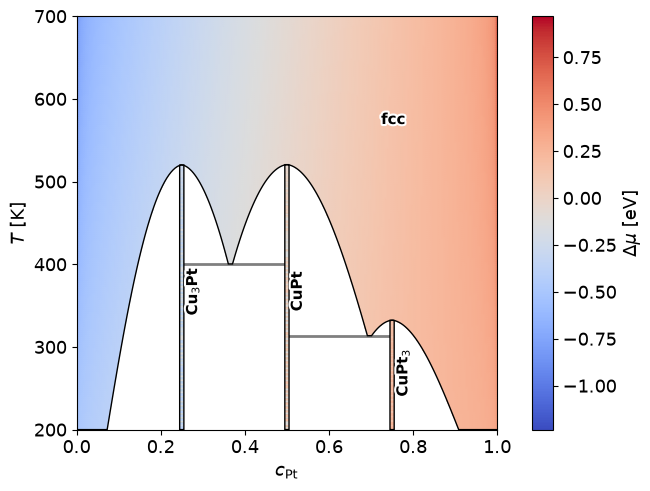

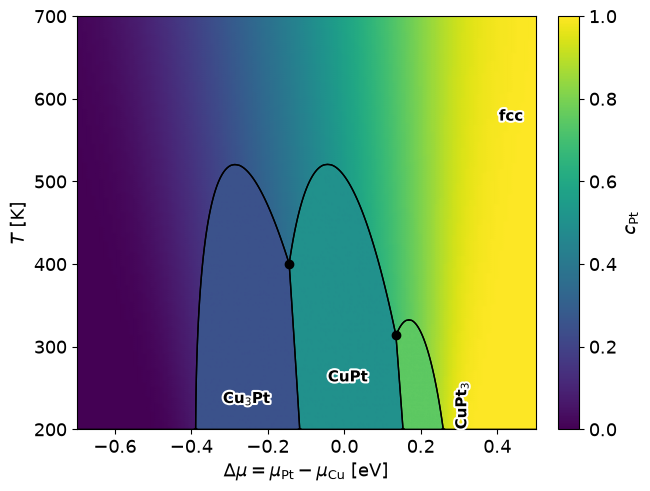

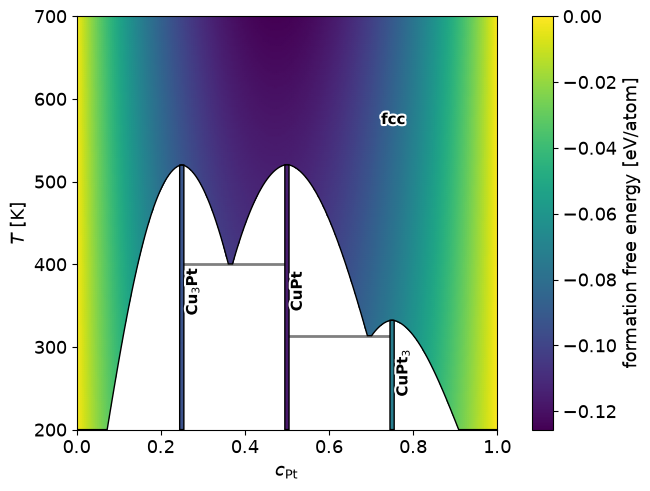

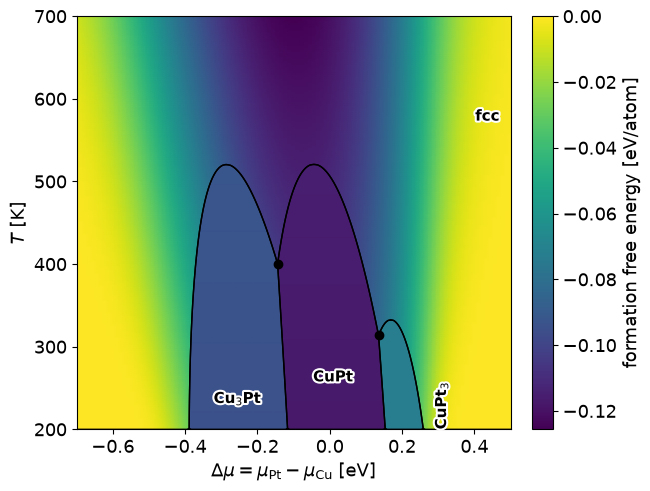

In [8]:
FIELDS = [  # (diagram, column, colour bar label, colour map)
    ("cT", "mu", r"$\Delta\mu$ [eV]", "coolwarm"),
    ("muT", "c", r"$c_\mathrm{Pt}$", "viridis"),
    ("cT", "f_excess", "formation free energy [eV/atom]", "viridis"),
    ("muT", "f_excess", "formation free energy [eV/atom]", "viridis"),
]
for kind, column, label, cmap in FIELDS:
    fig, ax = plt.subplots(figsize=FIGSIZE, layout="constrained")
    PLOTS[kind](diagram, ax=ax, element=B, color_by=column, cmap=cmap, triplepoints=True)
    finish(ax, kind)
    fig.axes[-1].set_ylabel(label)
    save(fig, f"CuPt_{kind}_by_{column}")